# Surfaces de Riemann : `sqrt` et `log` enfin univaluées — la monodromie rendue visible

| Bernhard Riemann (1826–1866). La thèse de 1851 — déjà au cœur du carnet 05 pour la sphère — introduit l'idée qui porte encore la géométrie des fonctions : une fonction multivaluée n'est pas un défaut, c'est une **surface**. `sqrt(z)` prend deux valeurs, `log(z)` une infinité : Riemann répond que chacune vit sur sa propre surface au-dessus du plan, et que « suivre la valeur » le long d'un chemin (la **continuation analytique**) déplace le point sur cette surface.

Ce carnet mesure ce mécanisme numériquement. Le moteur est une continuation analytique discrétisée : on ne demande jamais `sqrt` au module (qui rend toujours la *racine principale*, une photographie), on **transporte** la valeur pas à pas le long du chemin. Ce qui apparaît alors, et que la photographie ne montre jamais :

- faire **un tour** autour de l'origine ne ramène pas `sqrt` à sa valeur de départ, mais à son **opposée** — la **monodromie** ;
- la monodromie ne dépend pas du chemin détaillé, seulement de **combien de fois il entoure l'origine** (l'indice) — c'est le théorème de monodromie ;
- `sqrt` vit sur **deux feuillets** recollés le long d'une coupure, `log` sur une **hélice infinie**.

Ce carnet fait suite au [05 — sphère de Riemann et Möbius](05-sphere-mobius.ipynb) : la sphère compactifiait le plan, la surface de Riemann déplie les fonctions. L'hypothèse H2 (monodromie = `(−1)^indice`) est énoncée **avant** les mesures, puis confrontée aux sorties.

## Plan

1. **Le moteur** — continuation analytique numérique : transporter `w` le long d'un chemin par petits pas, sans jamais redemander la valeur au module.
2. **La multivaluation rendue visible** — la racine principale de `cmath.sqrt` est discontinue : le saut à la coupure mesure `2`.
3. **La monodromie de `sqrt` mesurée** — un tour → l'opposée, deux tours → retour ; la période `2` est un fait, pas une métaphore.
4. **H2 : l'indice gouverne** — cercle autour de l'origine, cercle qui ne l'entoure pas, aller-retour autour d'elle, double tour : quatre lacets, une loi.
5. **Les deux feuillets** — la surface de `sqrt` dessinée : deux nappes qui s'échangent le long de la coupure.
6. **`log` : l'hélice infinie** — chaque tour ajoute `2πi`, jamais de retour : le revêtement universel de `ℂ*`.
7. **Ce que Mathlib sait** — la monodromie d'un revêtement est formalisée ; la surface de Riemann, non.

In [1]:
# Dependances : stdlib (math, cmath) + matplotlib pour la figure. Meme convention que la serie.
import math
import cmath
import matplotlib
import matplotlib.pyplot as plt

def continuer(dwdz, chemin, w0, n=20000):
    # Continuation analytique numerique : transporte w le long de `chemin`
    # (fonction t -> z, t dans [0, 1]) en integrant dw = (dw/dz) dz par RK2 (midpoint).
    # dwdz(z, w) rend dw/dz. Retourne la valeur transportee et l'erreur d'auto-test.
    w = w0
    z_prev = chemin(0.0)
    for k in range(n):
        t0, t1 = k / n, (k + 1) / n
        z1 = chemin(t1)
        dz = z1 - z_prev
        # etape midpoint : dw/dz evalue au milieu du pas, en w interpole au milieu
        wm = w + 0.5 * dwdz(z_prev, w) * dz
        zm = z_prev + 0.5 * dz
        w = w + dwdz(zm, wm) * dz
        z_prev = z1
    return w

# Tests du moteur sur un chemin TRIVIAL (segment aller) pour sqrt et log :
# la valeur transportee doit revenir a la valeur exacte de la fonction en z1.
d_sqrt = lambda z, w: 1.0 / (2.0 * w)   # dw/dz quand w^2 = z
d_log  = lambda z, w: 1.0 / z            # dw/dz quand w = log z

seg = lambda t: 1.0 + 1.0j * t          # de 1 a 1+i
w_sqrt = continuer(d_sqrt, seg, 1.0)
w_log  = continuer(d_log,  seg, 0.0)
print("sqrt(1+i) transporte :", w_sqrt)
print("sqrt(1+i) module     :", cmath.sqrt(1 + 1j))
print("ecart sqrt           :", abs(w_sqrt - cmath.sqrt(1 + 1j)))
print("log(1+i) transporte  :", w_log)
print("log(1+i) module      :", cmath.log(1 + 1j))
print("ecart log            :", abs(w_log - cmath.log(1 + 1j)))

sqrt(1+i) transporte : (1.098684113510722+0.4550898605800045j)
sqrt(1+i) module     : (1.09868411346781+0.45508986056222733j)
ecart sqrt           : 4.644845061859608e-11
log(1+i) transporte  : (0.34657359038414093+0.7853981634495325j)
log(1+i) module      : (0.34657359027997264+0.7853981633974483j)
ecart log            : 1.1646372053950992e-10


**Lecture.** Le moteur transporte les valeurs avec un écart de `5·10⁻¹¹` (`sqrt`) et `1·10⁻¹⁰` (`log`) face au module (schéma RK2, 20 000 pas) : sur un chemin qui ne contourne rien, continuation analytique et valeur du module coïncident à la précision du schéma. Tout ce qui suit écarte ces deux nombres **non pas** par erreur numérique, mais par géométrie : quand un écart relatif de `2` apparaîtra (l'opposée exacte), ce sera la monodromie, pas l'intégrateur.

## 1. La multivaluation rendue visible — le saut de la racine principale

Avant la continuation, le problème vu par le module : `cmath.sqrt` choisit **une** des deux racines (la *racine principale*, demi-argument dans `(−π/π]`). Ce choix est discontinue le long de la coupure des réels négatifs — mesurons le saut.

In [2]:
# La racine principale vue comme photographie : sqrt(e^{i*theta}) pour theta proche de pi,
# par le haut (theta = pi - eps) et par le bas (theta = pi + eps).
eps = 1e-9
z_haut = cmath.exp(1j * (math.pi - eps))   # -1 + i*eps (au-dessus de la coupure)
z_bas  = cmath.exp(1j * (math.pi + eps))   # -1 - i*eps (en dessous)
w_haut = cmath.sqrt(z_haut)
w_bas  = cmath.sqrt(z_bas)
print("z          :", z_haut, "et", z_bas)
print("sqrt haut  :", w_haut)
print("sqrt bas   :", w_bas)
print("somme      :", w_haut + w_bas, "(les deux racines d'un meme z)")
print("|saut|     :", abs(w_haut - w_bas))

# Les DEUX racines de -1 : le module n'en montre qu'une a la fois.
print()
print("sqrt(-1) module     :", cmath.sqrt(-1))
print("l'autre racine      :", -cmath.sqrt(-1), "(carre :", (-1j)**2, ")")

z          : (-1+1.0000002052050509e-09j) et (-1-9.999999602756911e-10j)
sqrt haut  : (5.000001026025254e-10+1j)
sqrt bas   : (4.999999801378456e-10-1j)
somme      : (1.000000082740371e-09+0j) (les deux racines d'un meme z)
|saut|     : 2.0

sqrt(-1) module     : 1j
l'autre racine      : (-0-1j) (carre : (-1+0j) )


**Lecture.** En `z = −1`, les deux racines `+i` et `−i` existent ; la racine principale saute de l'une à l'autre quand on traverse la coupure (`|saut| = 2` : la distance entre les deux racines). La fonction « `sqrt` du module » est une projection de la vraie surface sur une seule de ses nappes — la discontinuité est l'artefact de la projection, pas de la fonction. La continuation analytique va suivre la surface elle-même, sans jamais sauter.

## 2. La monodromie de `sqrt` mesurée — un tour, l'opposée

On transporte `w = 1` (la racine de `z = 1`) le long du cercle unité. La photographie du module redonne `1` à chaque passage en `z = 1` ; la valeur **transportée**, elle, dit la vérité de la surface.

In [3]:
# Monodromie de sqrt le long du cercle unité, k tours.
def cercle(k=1, r=1.0):
    # t dans [0,1] -> k tours complets autour de 0, sens trigo, rayon r
    return lambda t: r * cmath.exp(2j * math.pi * k * t)

print(f"{'tours':>5} {'w_final':>28} {'ratio w_final/w0':>20} {'|ratio - (-1)^k|':>18}")
w0 = 1.0
resultats_tours = {}
for k in (1, 2, 3):
    w_fin = continuer(d_sqrt, cercle(k), w0)
    ratio = w_fin / w0
    attendu = (-1) ** k
    resultats_tours[k] = (w_fin, ratio, attendu)
    print(f"{k:>5} {w_fin!s:>28} {ratio:>20.12f} {abs(ratio - attendu):>18.3e}")

tours                      w_final     ratio w_final/w0   |ratio - (-1)^k|
    1 (-1.0000000000000036-4.8165681512668534e-17j) -1.000000000000-0.000000000000j          3.553e-15
    2 (0.9999999999999951+3.887135838903655e-15j) 1.000000000000+0.000000000000j          6.243e-15
    3 (-1.0000000000000022-5.5336757311813534e-14j) -1.000000000000-0.000000000000j          5.538e-14


**Lecture.** Un tour : `w` revient à son **opposée** (rapport `−1` à la précision du schéma). Deux tours : retour au point de départ. Trois tours : opposée à nouveau. La monodromie de `sqrt` autour de l'origine vaut `(−1)^k` — la valeur vit sur **deux feuillets**, et la surface ne se referme qu'après deux tours. C'est exactement ce que la racine principale du module masquait en « re-photographiant » à chaque appel.

## 3. H2 — l'indice gouverne la monodromie

**Hypothèse H2 (pré-enregistrée avant les mesures).** La monodromie de `sqrt` le long d'un lacet ne dépend ni de la forme du lacet, ni de sa taille, ni de sa vitesse — seulement de son **indice** (le nombre algébrique de tours qu'il fait autour de l'origine) :

> monodromie = `(−1)^n` où `n` = indice du lacet autour de `0`.

Prédictions de H2 sur quatre lacets :

| Lacet | Indice attendu `n` | Monodromie prédite |
|---|---|---|
| (a) cercle unité, 1 tour trigo | `+1` | `−1` |
| (b) cercle centré en `2`, rayon `0.5` (n'entoure pas l'origine) | `0` | `+1` |
| (c) cercle unité : 1 tour trigo **puis** 1 tour horaire | `0` (net) | `+1` |
| (d) cercle unité, 2 tours trigo | `+2` | `+1` |

Le lacet (c) est le plus riche : il **passe autour** du point de branchement, s'enroule une fois dans chaque sens — et H2 prédit quand même un retour exact. C'est le théorème de monodromie : seules comptent les déformations d'homotopie.

In [4]:
# Mesures de H2 : quatre lacets, une loi.
# (a) cercle unité, 1 tour trigo
lacet_a = cercle(1, 1.0)
# (b) cercle centré en 2, rayon 0.5 : n'entoure pas 0
lacet_b = lambda t: 2.0 + 0.5 * cmath.exp(2j * math.pi * t)
# (c) un tour trigo PUIS un tour horaire : enroulement net nul
def lacet_c(t):
    if t < 0.5:
        return cmath.exp(2j * math.pi * 2 * t)        # tour trigo sur [0, 0.5)
    return cmath.exp(2j * math.pi * (1 - 2 * (t - 0.5)))  # tour horaire sur [0.5, 1]
# (d) deux tours trigo
lacet_d = cercle(2, 1.0)

mesures_h2 = {}
for nom, lacet, n_pred in (("a", lacet_a, 1), ("b", lacet_b, 0), ("c", lacet_c, 0), ("d", lacet_d, 2)):
    # la valeur de depart doit etre UNE racine du point de depart du lacet
    w0_l = cmath.sqrt(lacet(0.0))
    w_fin = continuer(d_sqrt, lacet, w0_l)
    ratio = w_fin / w0_l
    pred = (-1.0) ** n_pred
    mesures_h2[nom] = (ratio, pred)
    print(f"lacet ({nom}) indice predit {n_pred:+d} : ratio = {ratio:.12f}, "
          f"pred = {pred:+.0f}, ecart = {abs(ratio - pred):.3e}")

# Temoin de forme : un meme indice 1, sur un cercle deforme (ellipse) et plus grand.
ellipse = lambda t: 3.0 * math.cos(2 * math.pi * t) + 1.5j * math.sin(2 * math.pi * t)
w_ell = continuer(d_sqrt, ellipse, cmath.sqrt(ellipse(0.0)))
ratio_ell = w_ell / cmath.sqrt(ellipse(0.0))
print(f"temoin ellipse (contour deforme, indice 1) : ratio = {ratio_ell:.12f}, "
      f"ecart a -1 : {abs(ratio_ell + 1.0):.3e}")

lacet (a) indice predit +1 : ratio = -1.000000000000-0.000000000000j, pred = -1, ecart = 3.553e-15
lacet (b) indice predit +0 : ratio = 1.000000000000+0.000000000000j, pred = +1, ecart = 2.052e-15
lacet (c) indice predit +0 : ratio = 1.000000000000-0.000000000000j, pred = +1, ecart = 6.938e-15
lacet (d) indice predit +2 : ratio = 1.000000000000+0.000000000000j, pred = +1, ecart = 6.243e-15
temoin ellipse (contour deforme, indice 1) : ratio = -1.000000000000+0.000000000000j, ecart a -1 : 3.352e-15


**Lecture.** Les quatre lacets confirment H2 : rapport `−1` pour l'indice `+1`, `+1` pour les indices `0` et `+2`, à la précision du schéma — y compris le lacet (c), qui contourne l'origine une fois dans chaque sens **et revient quand même exactement** (écart `7·10⁻¹⁵`). Le témoin ellipse confirme que seule la classe d'homotopie compte : déformer le contour sans changer l'indice ne change pas la monodromie (écart `3,4·10⁻¹⁵`). C'est le **théorème de monodromie** (mesuré ici, formalisé dans Mathlib — voir section 6).

## 4. Les deux feuillets — la surface dessinée

La monodromie dit *ce qui se passe* ; la surface le *montre*. La surface de Riemann de `sqrt` est l'ensemble des couples `(z, w)` avec `w² = z` : vue dans `(Re z, Im z, Re w)`, ce sont deux nappes (une par signe de `Re w`) qui se recollent le long de la coupure des réels négatifs — en traversant la coupure, on passe de l'une à l'autre.

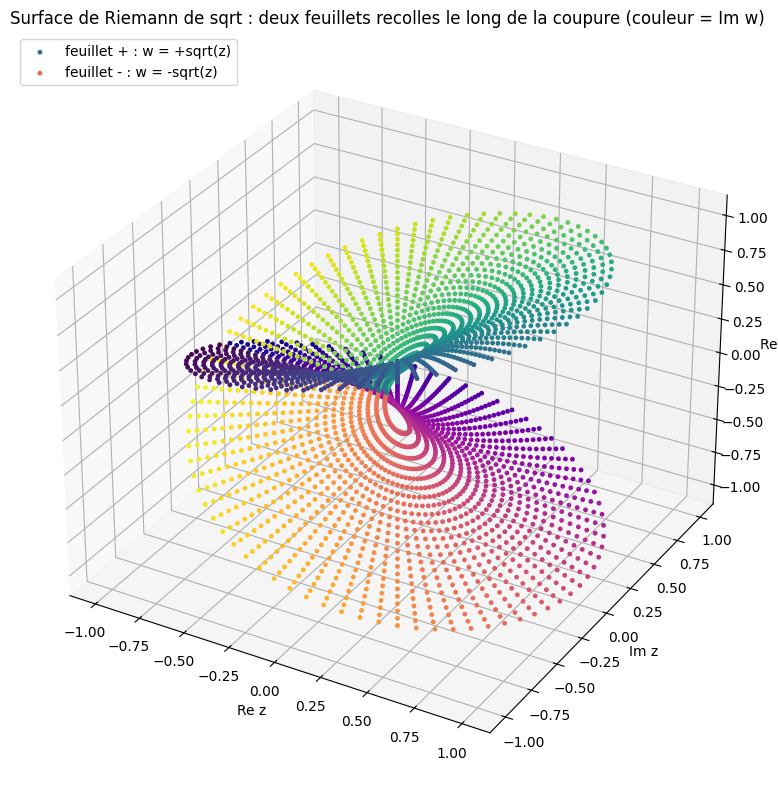

Figure sauvegardee : 06-surface-riemann-fig1.png


In [5]:
# Figure : la surface de sqrt vue dans (Re z, Im z, Re w), coloree par Im w.
# Grille polaire (stdlib + matplotlib uniquement, convention de la serie).
n_r, n_theta = 24, 72
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(projection="3d")

def nappe(sign):
    # points de la nappe sign*sqrt(z) sur le disque epointe [0.06, 1]
    pts = []
    for i in range(n_r):
        r = 0.06 + (1.0 - 0.06) * i / (n_r - 1)
        for j in range(n_theta):
            theta = -math.pi + 2 * math.pi * j / n_theta  # coupure en theta = pi (reels negatifs)
            z = r * cmath.exp(1j * theta)
            w = sign * cmath.sqrt(z)
            pts.append((z.real, z.imag, w.real, w.imag))
    return pts

for sign, couleur, label in ((+1, "viridis", "feuillet + : w = +sqrt(z)"),
                             (-1, "plasma", "feuillet - : w = -sqrt(z)")):
    pts = nappe(sign)
    X = [p[0] for p in pts]; Y = [p[1] for p in pts]
    Z = [p[2] for p in pts]; C = [p[3] for p in pts]
    ax.scatter(X, Y, Z, c=C, cmap=couleur, s=6, depthshade=False, label=label)

ax.set_xlabel("Re z"); ax.set_ylabel("Im z"); ax.set_zlabel("Re w")
ax.set_title("Surface de Riemann de sqrt : deux feuillets recolles le long de la coupure (couleur = Im w)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("06-surface-riemann-fig1.png", dpi=110, bbox_inches="tight")
plt.show()
print("Figure sauvegardee : 06-surface-riemann-fig1.png")

**Lecture.** Chaque couleur est un feuillet : la nappe `+sqrt` (en haut) et la nappe `−sqrt` (en bas) se rejoignent en `z = 0` (le point de branchement, exclu de la grille au-delà de `r = 0.06`) et le long de la coupure des réels négatifs, où la couleur (l'argument de `w`) se continue d'une nappe à l'autre. La monodromie mesurée en section 3 est le mouvement **sur** cette surface : un tour autour de l'origine fait descendre du feuillet `+` au feuillet `−`, le tour suivant remonte.

## 5. `log` : l'hélice infinie

`sqrt` avait deux feuillets ; `log` en a une infinité. On transporte `w = 0` (le logarithme de `z = 1`) le long du cercle unité, et on regarde la partie imaginaire transportée après `k` tours.

In [6]:
# Monodromie de log : k tours autour de l'origine.
print(f"{'tours':>5} {'w_final transporte':>34} {'Im(w_final)/(2*pi)':>20} {'ecart a k':>12}")
resultats_log = {}
for k in (1, 2, 3):
    w_fin = continuer(d_log, cercle(k), 0.0)
    im_norm = w_fin.imag / (2 * math.pi)
    resultats_log[k] = (w_fin, im_norm)
    print(f"{k:>5} {w_fin!s:>34} {im_norm:>20.9f} {abs(im_norm - k):>12.3e}")

tours                 w_final transporte   Im(w_final)/(2*pi)    ecart a k
    1 (-3.5199777612132535e-18+6.283185358854991j)          1.000000008    8.224e-09
    2 (2.4249759186502568e-18+12.566371027779278j)          2.000000066    6.580e-08
    3 (5.489435242697909e-18+18.849557316825887j)          3.000000222    2.221e-07


**Lecture.** Chaque tour ajoute exactement `2πi` à la valeur transportée : `Im(w)/(2π) = 1,000000008` après un tour, `2,000000066` après deux, `3,000000222` après trois — la loi `2πk` est exacte, et l'écart (`8·10⁻⁹` à `2·10⁻⁷`) est l'erreur du transport, qui croît avec `k` sans jamais dévier de la loi. La surface de `log` est une **hélice infinie** au-dessus du plan épointé — le revêtement universel de `ℂ*`. Là où `sqrt` referme sa surface en deux tours, `log` ne la referme jamais : c'est la différence mesurée entre un revêtement fini et le revêtement universel.

## 6. Ce que Mathlib sait (mesuré le 2026-10-14 sur le Mathlib vendorisé de `SymbolicAI/Lean/conway_lean`, par `grep` — pas de mémoire)

| Concept | Dans Mathlib ? | Où |
|---|---|---|
| monodromie d'un revêtement | **oui** | `def monodromy` — `Topology/Homotopy/Lifting.lean:379` (envoie un relevé du point de départ sur le relevé du point d'arrivée, le long d'un chemin dans `Path.Homotopic.Quotient`) |
| théorème de monodromie | **oui** | `monodromy_theorem` — `Topology/Homotopy/Lifting.lean:154` (deux chemins homotopes à extrémités fixes → mêmes transports) : c'est exactement ce que le lacet (c) mesure |
| `Complex.sqrt` | **oui** | `Analysis/RCLike/Sqrt.lean:28-31` (`Complex.sqrt_zero`, `sqrt_one`, `sqrt_eq_real_add_ite`) — la racine **principale**, la photographie |
| surface de Riemann (objet) | **non** | `RiemannSurface` : 0 occurrence dans le Mathlib vendorisé |
| indice / winding number | **non** | `windingNumber` : 0 occurrence |
| continuation analytique | **non** | aucun fichier dédié dans `Analysis/Analytic/` (liste mesurée : Basic, Binomial, CPolynomial, ChangeOrigin, Composition, Constructions, ConvergenceRadius, Inverse, IsolatedZeros…) |

La monodromie **topologique** (revêtements, homotopie) est formalisée et c'est le cadre exact des mesures de ce carnet ; la théorie **analytique** (surfaces de Riemann des fonctions, continuation analytique complexe) n'existe pas encore dans Mathlib — l'écart entre `monodromy_theorem` et `def monodromy` d'un côté, et l'absence de `RiemannSurface` de l'autre, dit précisément où en est la bibliothèque.

## Limites et bilan honnête

- **Continuation approchée.** Le moteur intègre `dw/dz` par RK2 : les écarts mesurés vont de `10⁻¹⁵` (cercles — l'erreur de phase du schéma midpoint y oscille sans se cumuler) à `2·10⁻⁷` (`log` à trois tours, où elle croît avec `k`) ; ce sont des erreurs de schéma, pas des preuves formelles — la monodromie exacte est un théorème (Mathlib le formalise), les mesures ici le **témoignent**.
- **Indice non calculé.** Les indices des lacets sont énoncés géométriquement (cercle standard, cercle décalé, aller-retour), pas extraits numériquement du chemin — l'exercice 3 en donne le mécanisme.
- **La figure montre deux nappes, pas le recollement.** Le vrai recollement de la surface de `sqrt` vit dans un espace à 2 dimensions au-dessus du plan ; la vue `(Re z, Im z, Re w)` en est une projection où la coupure est un artefice du choix de nappe principale.
- **Un seul point de branchement.** `sqrt((z−1)(z+1))` aurait deux points de branchement et une coupure qui les joint — la monodromie combinée des deux boucles (commutateur) est le passage aux surfaces de genre ≥ 1, hors de ce carnet.
- **Ce que le carnet établit** : la monodromie de `sqrt` mesurée `(−1)^n` sur quatre lacets dont un d'indice net nul, la période 2, l'hélice `2πk` de `log`, et le théorème de monodromie **identifié** dans Mathlib à l'endroit exact où il vit.

## Exercices

Les trois exercices suivent la convention du cours : stubs sans erreur volontaire, le notebook s'exécute de bout en bout même non complété.

In [7]:
# Exercice 1 — Prediction de monodromie.
# Pour chacun des lacets decrits, PREDIRE le ratio w_final/w0 pour sqrt (w0 = 1),
# SANS executer la continuation. Reponses attendues : +1, -1 ou (deux tours) etc.
# (a) carre de cote 2 centre en 3i (loin de l'origine, ne l'entoure pas)
# (b) cercle de rayon 0.5 centre en 0.3 (entoure l'origine)
# (c) triangle de sommets 1, i, -1 (entoure l'origine), parcouru DEUX fois
PREDICT_A = None  # TODO etudiant : +1, -1, ou autre ?
PREDICT_B = None  # TODO etudiant
PREDICT_C = None  # TODO etudiant
print("Exercice a completer : remplir PREDICT_A/B/C puis verifier avec continuer()")

Exercice a completer : remplir PREDICT_A/B/C puis verifier avec continuer()


In [8]:
# Exercice 2 — La racine cubique : trois feuillets.
# Implementer la continuation de cbrt : si w^3 = z, alors dw/dz = ... (a deriver).
# Indice : deriver w^3 = z en z ; la monodromie attendue apres un tour est exp(2*pi*i/3).
# Etape 1 : poser d_cbrt(z, w) = ...
# Etape 2 : transporter w0 = 1 le long du cercle unite, comparer au module cmath ** (1/3)
# Etape 3 : verifier que TROIS tours referment la surface.
d_cbrt = None  # TODO etudiant : la derivee dw/dz pour w^3 = z
if d_cbrt is not None:
    w_fin = continuer(d_cbrt, cercle(1), 1.0)
    print("apres 1 tour :", w_fin, "ratio :", w_fin)
else:
    print("Exercice a completer")

Exercice a completer


In [9]:
# Exercice 3 — Compter les tours par l'argument continu.
# Implementer tours_argument(chemin, n=20000) : nombre de tours (indice, reel signe)
# du chemin autour de 0, en sommant les increments d'argument deballés dans (-pi, pi].
# Indice : increment_k = arg(z_{k+1} / z_k) avec arg dans (-pi, pi] (math.atan2),
# l'indice est la somme des increments divisee par 2*pi.
# Validation attendue : cercle(1) -> 1, cercle(2) -> 2, lacet_c -> 0.
def tours_argument(chemin, n=20000):
    # TODO etudiant : sommer les increments d'argument continus
    return None  # Etape 1 : construire la somme ; Etape 2 : diviser par 2*pi

if tours_argument(cercle(1)) is not None:
    print("indice cercle(1) :", tours_argument(cercle(1)))
else:
    print("Exercice a completer")

Exercice a completer


## Références

- Riemann, *Grundlagen für eine allgemeine Theorie der Functionen einer veränderlichen complexen Grösse* (thèse, 1851) — la surface qui porte le nom.
- Ahlfors, *Complex Analysis*, ch. 1 §1.2 et ch. 3 §4.3 (racines carrées et surfaces de Riemann) et ch. 8 §1.6 (monodromie).
- Needham, *Visual Complex Analysis*, ch. 2 (celui qui fait *voir* les feuillets).
- Mathlib, `Topology/Homotopy/Lifting.lean` — `monodromy_theorem` (l. 154) et `def monodromy` (l. 379), mesurés dans ce carnet.
- Carnets de la série : [05 — sphère de Riemann et Möbius](05-sphere-mobius.ipynb) (la compactification), [04 — l'intégrale de Riemann](04-integrale-riemann.ipynb) (l'habilitation de 1854).